In [1]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

In [14]:
from skimage.feature import blob_log
from scipy.ndimage import maximum_filter

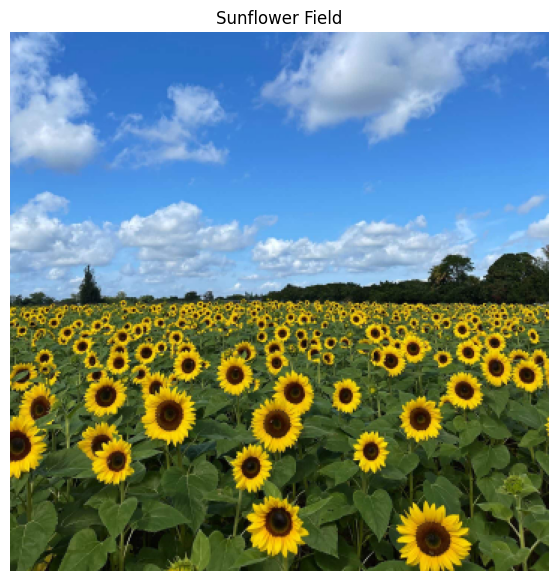

In [10]:
#Load the reduced resolution image
im=cv.imread(r'C:\Users\shala\Desktop\IP\A02 _Fitting and Alignment\EN3160-Assignment-2-on-Fitting-and-Alignment\a2images\a2images\the_berry_farms_sunflower_field.jpeg',cv.IMREAD_REDUCED_COLOR_4)
if im is None:
    raise FileNotFoundError("Couldn't load the sunflower image.")
#Convert BGR to RGB and grayscale
im_rgb=cv.cvtColor(im,cv.COLOR_BGR2RGB)
gray=cv.cvtColor(im,cv.COLOR_BGR2GRAY)
gray=gray.astype(np.float32)/255.0
plt.figure(figsize=(10, 7))
plt.imshow(im_rgb)
plt.title("Sunflower Field")
plt.axis("off")
plt.show()



In [93]:
sigmas=np.geomspace(0.001,11.0,25)    #sigma values to investigate
scale_space=[]  
for sigma in sigmas:
    blurred=cv.GaussianBlur(gray,(0,0),sigmaX=float(sigma),sigmaY=float(sigma))
    laplacian=cv.Laplacian(blurred,cv.CV_32F,ksize=3)
    normalized_log=(sigma**2)*laplacian
    output=normalized_log**2
    scale_space.append(output)
scale_space = np.stack(scale_space, axis=0)
#print(scale_space)

In [94]:
local_max = maximum_filter(scale_space, size=(3, 3, 3))
threshold_rel = 0.6
threshold = threshold_rel * np.max(scale_space)
peak_mask = (scale_space == local_max) & (scale_space > threshold)
scale_idx, ys, xs = np.where(peak_mask)
circles = []
for i, y, x in zip(scale_idx, ys, xs):
    sigma_value = float(sigmas[i])
    radius = int(round(2 * sigma_value))
    circles.append({"x": int(x),"y": int(y),"sigma": sigma_value,"radius": radius,"response": float(scale_space[i, y, x])})
print("No. of detected blobs:", len(circles))

No. of detected blobs: 40


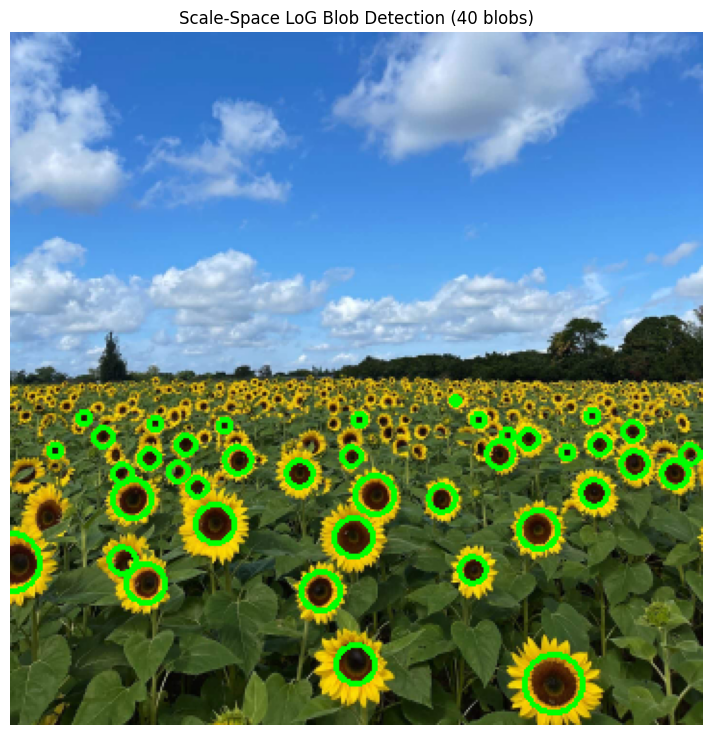

In [96]:
result = cv.cvtColor(im, cv.COLOR_BGR2RGB)
for circle in circles:
    center = (circle["x"], circle["y"])
    radius = circle["radius"]

    cv.circle(result,center,radius,(0, 255, 0),2)

plt.figure(figsize=(14, 9))
plt.imshow(result)
plt.title(f"Scale-Space LoG Blob Detection ({len(circles)} blobs)")
plt.axis("off")
plt.show()